# Preparación de datos para predicción de fraude
## Dataset `Fraude.csv`

**Alcance de esta entrega:** comprensión del negocio, auditoría de calidad, análisis exploratorio y construcción de un conjunto preparado para una etapa posterior de modelado. No se entrena ni se selecciona todavía un modelo final.

La metodología sigue CRISP-DM: el problema de negocio determina qué datos utilizar, cómo evitar fugas de información y cuál debe ser la estrategia de validación.

## 1. Objetivo de negocio y criterio técnico

Se busca preparar información transaccional para que un modelo posterior estime si una operación es fraudulenta (`isFraud = 1`). El fraude es un evento raro: por eso la preparación debe preservar los positivos, evitar contaminar el futuro con información del pasado y documentar el costo de los errores.

- **Falso negativo:** fraude no detectado. En negocio puede representar pérdida financiera y exposición operativa.
- **Falso positivo:** transacción legítima retenida o revisada. Puede generar fricción, costo de revisión y deterioro de experiencia.
- **Criterio de éxito de esta etapa:** datos íntegros, variables reproducibles, partición temporal y ausencia de fuga evidente.

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
DATA_PATH=next((p for p in ["../data/Fraud.csv","Fraud.csv","Fraude.csv","/mnt/data/Fraude.csv"] if os.path.exists(p)),"Fraud.csv")

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"No se encontró '{DATA_PATH}'. Por favor, sube el archivo 'Fraude.csv' usando el panel de archivos de Google Colab (icono de carpeta a la izquierda) antes de ejecutar esta celda.")

df_raw=pd.read_csv(DATA_PATH)
print("Dimensión:",df_raw.shape)
display(df_raw.head())

Dimensión: (1362621, 12)


,Unnamed: 0,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,5003937,353,CASH_OUT,366837.00,C1378361187,0.0,0.0,C971468434,421675.19,558423.14,0,0
1,5003938,353,CASH_OUT,227225.22,C211071968,0.0,0.0,C1048278624,447213.34,674438.56,0,0
2,5003939,353,CASH_OUT,92507.74,C2120887021,0.0,0.0,C672681554,214510.10,307017.84,0,0
3,5003940,353,CASH_OUT,162519.57,C1103264078,0.0,0.0,C532824402,844653.01,1007172.59,0,0
4,5003941,353,CASH_OUT,157257.18,C1401140498,0.0,0.0,C700036764,2326697.36,2483954.55,0,0


El archivo contiene una columna adicional `Unnamed: 0`, que funciona como índice exportado. No representa una característica del comportamiento transaccional y se excluye. `isFlaggedFraud` también se elimina porque el enunciado indica expresamente no utilizarla.

## 2. Diccionario y auditoría estructural

In [2]:
audit=pd.DataFrame({
    "tipo":df_raw.dtypes.astype(str),
    "faltantes":df_raw.isna().sum(),
    "% faltantes":(df_raw.isna().mean()*100).round(4),
    "únicos":df_raw.nunique()
})
display(audit)
print("Duplicados exactos:",df_raw.duplicated().sum())
print("Rango de step:",df_raw.step.min(),"a",df_raw.step.max())
print("Steps distintos:",df_raw.step.nunique())

,tipo,faltantes,% faltantes,únicos
Unnamed: 0,int64,0,0.0,1362621
step,int64,0,0.0,742
type,str,0,0.0,5
amount,float64,0,0.0,1299642
nameOrig,str,0,0.0,1362202
oldbalanceOrg,float64,0,0.0,480253
newbalanceOrig,float64,0,0.0,586361
nameDest,str,0,0.0,917941
oldbalanceDest,float64,0,0.0,769027
newbalanceDest,float64,0,0.0,817405


Duplicados exactos: 0
Rango de step: 1 a 743
Steps distintos: 742


No se observan faltantes ni duplicados exactos. El rango temporal va de `step = 1` a `step = 743`; cada step equivale a una hora. La ausencia de nulos no elimina la necesidad de controlar valores cero, consistencia contable y distribuciones extremas.

## 3. Distribución de la variable objetivo

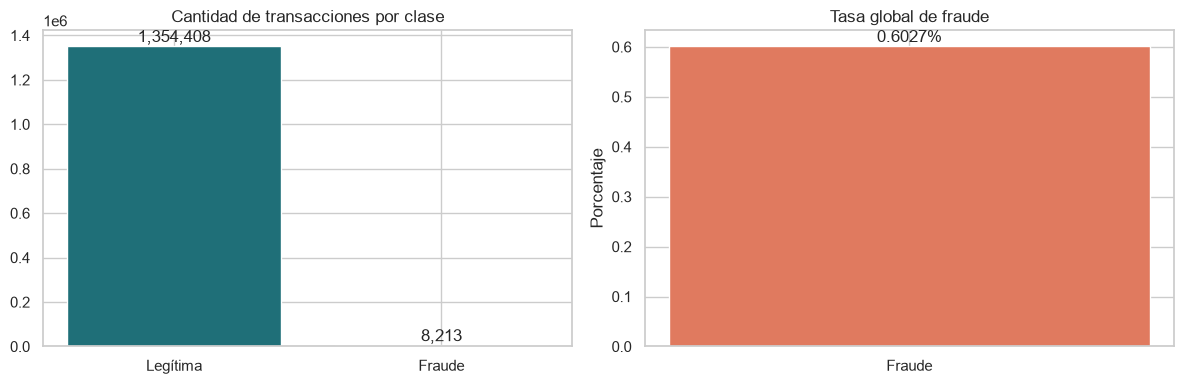

Fraudes: 8,213 de 1,362,621 (0.6027%)


In [3]:
target=df_raw.isFraud.value_counts().sort_index()
rate=df_raw.isFraud.mean()
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(["Legítima","Fraude"],target.values,color=["#1f6f78","#e07a5f"])
axes[0].set_title("Cantidad de transacciones por clase")
for b,v in zip(axes[0].patches,target.values): axes[0].text(b.get_x()+b.get_width()/2,v,f"{v:,}",ha="center",va="bottom")
axes[1].bar(["Fraude"],[rate*100],color="#e07a5f")
axes[1].set_title("Tasa global de fraude")
axes[1].set_ylabel("Porcentaje")
axes[1].text(0,rate*100,f"{rate:.4%}",ha="center",va="bottom")
plt.tight_layout(); plt.show()
print(f"Fraudes: {target.get(1,0):,} de {len(df_raw):,} ({rate:.4%})")

El dataset está fuertemente desbalanceado: sólo **0,6027%** de las operaciones son fraude. Esto condiciona todo el diseño posterior. No corresponde compensar el desbalance antes de separar entrenamiento y prueba, porque hacerlo sobre el total contaminaría la evaluación. En la etapa de modelado deberán priorizarse métricas como recall, precision, F1, PR-AUC y costo esperado, no accuracy aislada.

## 4. Tipos de transacción y concentración del fraude

,transacciones,fraudes,tasa_fraude,monto_mediano
type,,,,
CASH_OUT,467280,4116,0.8808%,"142,729.32"
PAYMENT,465158,0,0.0000%,"10,101.82"
CASH_IN,301286,0,0.0000%,"144,261.85"
TRANSFER,119163,4097,3.4381%,"484,482.06"
DEBIT,9734,0,0.0000%,"2,714.03"


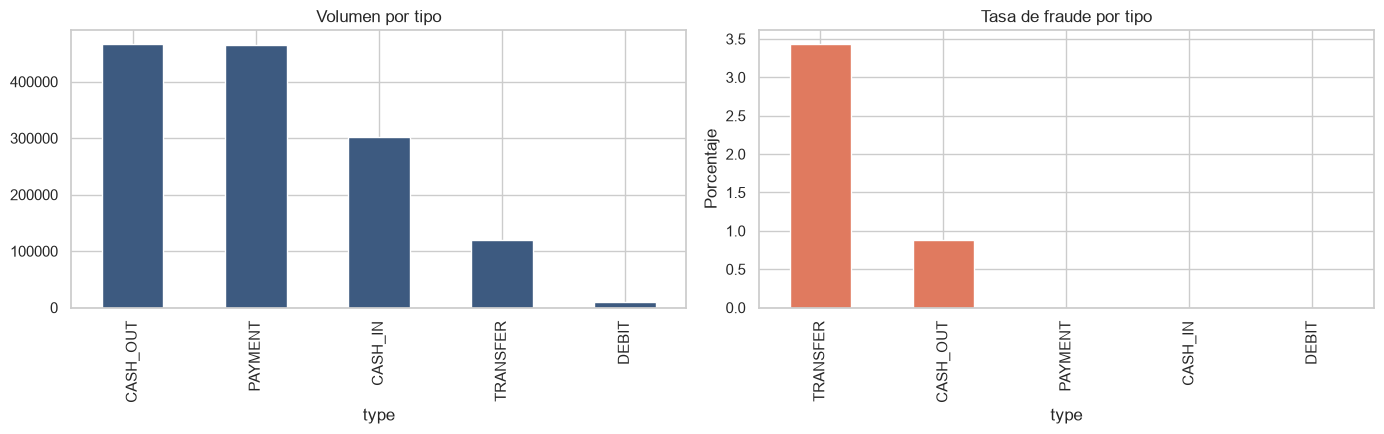

In [4]:
type_summary=df_raw.groupby("type").agg(
    transacciones=("isFraud","size"),
    fraudes=("isFraud","sum"),
    tasa_fraude=("isFraud","mean"),
    monto_mediano=("amount","median")
).sort_values("transacciones",ascending=False)
display(type_summary.style.format({"tasa_fraude":"{:.4%}","monto_mediano":"{:,.2f}"}))
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
type_summary.transacciones.plot(kind="bar",ax=axes[0],color="#3d5a80",title="Volumen por tipo")
(type_summary.tasa_fraude*100).sort_values(ascending=False).plot(kind="bar",ax=axes[1],color="#e07a5f",title="Tasa de fraude por tipo")
axes[1].set_ylabel("Porcentaje")
plt.tight_layout(); plt.show()

Los fraudes etiquetados aparecen únicamente en `TRANSFER` y `CASH_OUT`. Esto permite conservar el tipo como predictor categórico y anticipa que la capacidad de discriminación se concentrará en esos flujos. Sin embargo, no se deben eliminar automáticamente los demás tipos: hacerlo cambiaría el universo de decisión y podría producir un sistema incapaz de reconocer operaciones legítimas fuera de los tipos de mayor riesgo.

## 5. Distribución del monto

,count,mean,std,min,50%,90%,95%,99%,max
isFraud,,,,,,,,,
0,1354408.0,1.699845e+05,3.963902e+05,0.03,71818.12,356524.659,509610.411,1.682001e+06,19953778.06
1,8213.0,1.467967e+06,2.404253e+06,0.00,441423.44,4521723.512,8006429.040,1.000000e+07,10000000.00


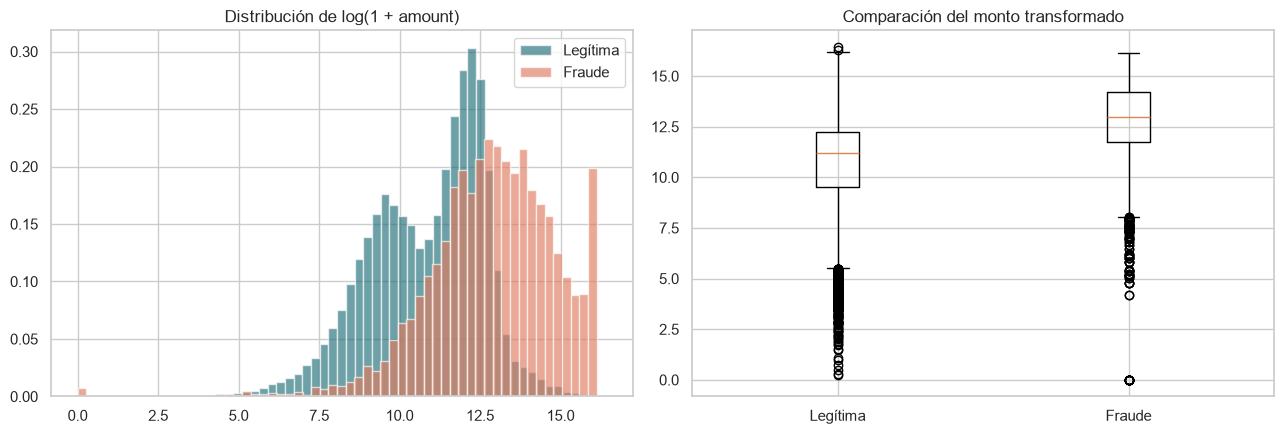

In [5]:
amount_summary=df_raw.groupby("isFraud").amount.describe(percentiles=[.5,.9,.95,.99])
display(amount_summary)
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
sample0=df_raw.loc[df_raw.isFraud.eq(0),"amount"].sample(100000,random_state=42)
sample1=df_raw.loc[df_raw.isFraud.eq(1),"amount"]
axes[0].hist(np.log1p(sample0),bins=60,alpha=.65,label="Legítima",density=True,color="#1f6f78")
axes[0].hist(np.log1p(sample1),bins=60,alpha=.65,label="Fraude",density=True,color="#e07a5f")
axes[0].set_title("Distribución de log(1 + amount)"); axes[0].legend()
axes[1].boxplot([np.log1p(sample0),np.log1p(sample1)],tick_labels=["Legítima","Fraude"])
axes[1].set_title("Comparación del monto transformado")
plt.tight_layout(); plt.show()

El monto es muy asimétrico y contiene valores extremos. Los fraudes presentan montos sustancialmente mayores en promedio y mediana. No se eliminan los importes elevados: podrían ser precisamente la señal relevante. Se crea `logAmount = log(1 + amount)` para reducir asimetría, conservando también el monto original para trazabilidad.

## 6. Ceros y consistencia de saldos

In [6]:
balance_cols=["oldbalanceOrg","newbalanceOrig","oldbalanceDest","newbalanceDest"]
zero_rates=(df_raw[balance_cols].eq(0).mean()*100).rename("% en cero")
display(zero_rates.to_frame())

expected_orig=np.where(df_raw.type.eq("CASH_IN"),df_raw.oldbalanceOrg+df_raw.amount,df_raw.oldbalanceOrg-df_raw.amount)
expected_dest=np.where(df_raw.type.eq("CASH_IN"),df_raw.oldbalanceDest-df_raw.amount,df_raw.oldbalanceDest+df_raw.amount)
orig_error=df_raw.newbalanceOrig-expected_orig
dest_error=df_raw.newbalanceDest-expected_dest
consistency=pd.DataFrame({
    "regla":["Saldo origen esperado","Saldo destino esperado"],
    "% coincidencia ±0.01":[np.isclose(orig_error,0,atol=.01).mean()*100,np.isclose(dest_error,0,atol=.01).mean()*100],
    "error absoluto mediano":[np.median(np.abs(orig_error)),np.median(np.abs(dest_error))]
})
display(consistency)

,% en cero
oldbalanceOrg,32.088967
newbalanceOrig,56.713716
oldbalanceDest,43.464397
newbalanceDest,38.754723


,regla,% coincidencia ±0.01,error absoluto mediano
0,Saldo origen esperado,41.249328,5519.29
1,Saldo destino esperado,51.392794,0.01


Los ceros son frecuentes y no deben tratarse como faltantes sin evidencia adicional: pueden representar saldo agotado, cuenta de comercio sin información de balance o una convención del simulador. La consistencia exacta entre monto y variación de saldo no se cumple en todas las filas; en lugar de corregir saldos, se crean **errores contables derivados** que pueden capturar anomalías operativas y se mantiene el dato original.

## 7. Identificadores de clientes y riesgo de fuga

In [7]:
id_summary=pd.DataFrame({
    "variable":["nameOrig","nameDest"],
    "únicos":[df_raw.nameOrig.nunique(),df_raw.nameDest.nunique()],
    "% cardinalidad":[df_raw.nameOrig.nunique()/len(df_raw)*100,df_raw.nameDest.nunique()/len(df_raw)*100]
})
display(id_summary)
print("Prefijos de destino:")
display(pd.crosstab(df_raw.nameDest.str[0],df_raw.type,normalize="columns").round(4))

,variable,únicos,% cardinalidad
0,nameOrig,1362202,99.969250
1,nameDest,917941,67.365834


Prefijos de destino:


type,CASH_IN,CASH_OUT,DEBIT,PAYMENT,TRANSFER
nameDest,,,,,
C,1.0,1.0,1.0,0.0,1.0
M,0.0,0.0,0.0,1.0,0.0


`nameOrig` tiene cardinalidad casi igual al número de filas. Aplicar One-Hot Encoding generaría una matriz enorme y favorecería la memorización. Los identificadores crudos no se utilizarán directamente. Se preserva el prefijo del destino (`C` o `M`) y se deja preparada una función de frecuencia que debe ajustarse **sólo sobre entrenamiento** para evitar usar información futura.

## 8. Ingeniería de variables reproducible

In [8]:
def add_transaction_features(data):
    out=data.copy()
    out=out.drop(columns=["Unnamed: 0","isFlaggedFraud"],errors="ignore")
    out["hourOfDay"]=(out["step"]-1)%24
    out["day"]=(out["step"]-1)//24+1
    out["isNight"]=out["hourOfDay"].between(0,5).astype("int8")
    out["logAmount"]=np.log1p(out["amount"])
    out["origBalanceDelta"]=out["newbalanceOrig"]-out["oldbalanceOrg"]
    out["destBalanceDelta"]=out["newbalanceDest"]-out["oldbalanceDest"]
    expected_orig=np.where(out.type.eq("CASH_IN"),out.oldbalanceOrg+out.amount,out.oldbalanceOrg-out.amount)
    expected_dest=np.where(out.type.eq("CASH_IN"),out.oldbalanceDest-out.amount,out.oldbalanceDest+out.amount)
    out["origBalanceError"]=out.newbalanceOrig-expected_orig
    out["destBalanceError"]=out.newbalanceDest-expected_dest
    out["origZeroBefore"]=out.oldbalanceOrg.eq(0).astype("int8")
    out["origZeroAfter"]=out.newbalanceOrig.eq(0).astype("int8")
    out["destZeroBefore"]=out.oldbalanceDest.eq(0).astype("int8")
    out["destZeroAfter"]=out.newbalanceDest.eq(0).astype("int8")
    out["destPrefix"]=out.nameDest.str[0]
    out["amountToOrigBalance"]=out.amount/(out.oldbalanceOrg.abs()+1)
    out["amountToDestBalance"]=out.amount/(out.oldbalanceDest.abs()+1)
    return out

prepared=add_transaction_features(df_raw)
new_cols=[c for c in prepared.columns if c not in df_raw.columns]
print("Variables derivadas:",new_cols)
display(prepared[new_cols+["isFraud"]].head())

Variables derivadas: ['hourOfDay', 'day', 'isNight', 'logAmount', 'origBalanceDelta', 'destBalanceDelta', 'origBalanceError', 'destBalanceError', 'origZeroBefore', 'origZeroAfter', 'destZeroBefore', 'destZeroAfter', 'destPrefix', 'amountToOrigBalance', 'amountToDestBalance']


,hourOfDay,day,isNight,logAmount,origBalanceDelta,destBalanceDelta,origBalanceError,destBalanceError,origZeroBefore,origZeroAfter,destZeroBefore,destZeroAfter,destPrefix,amountToOrigBalance,amountToDestBalance,isFraud
0,16,15,0,12.812676,0.0,136747.95,366837.00,-230089.05,1,1,0,0,C,366837.00,0.869950,0
1,16,15,0,12.333701,0.0,227225.22,227225.22,0.00,1,1,0,0,C,227225.22,0.508090,0
2,16,15,0,11.435058,0.0,92507.74,92507.74,0.00,1,1,0,0,C,92507.74,0.431249,0
3,16,15,0,11.998560,0.0,162519.58,162519.57,0.01,1,1,0,0,C,162519.57,0.192410,0
4,16,15,0,11.965644,0.0,157257.19,157257.18,0.01,1,1,0,0,C,157257.18,0.067588,0


Las variables derivadas traducen la transacción a señales más cercanas al comportamiento: hora, día, operación nocturna, escalamiento del monto, variaciones y errores de balance, ceros antes/después, prefijo de destinatario y proporciones monto/saldo. Todas pueden calcularse al momento de autorizar una operación, por lo que no introducen información posterior a la etiqueta.

## 9. Análisis temporal y deriva

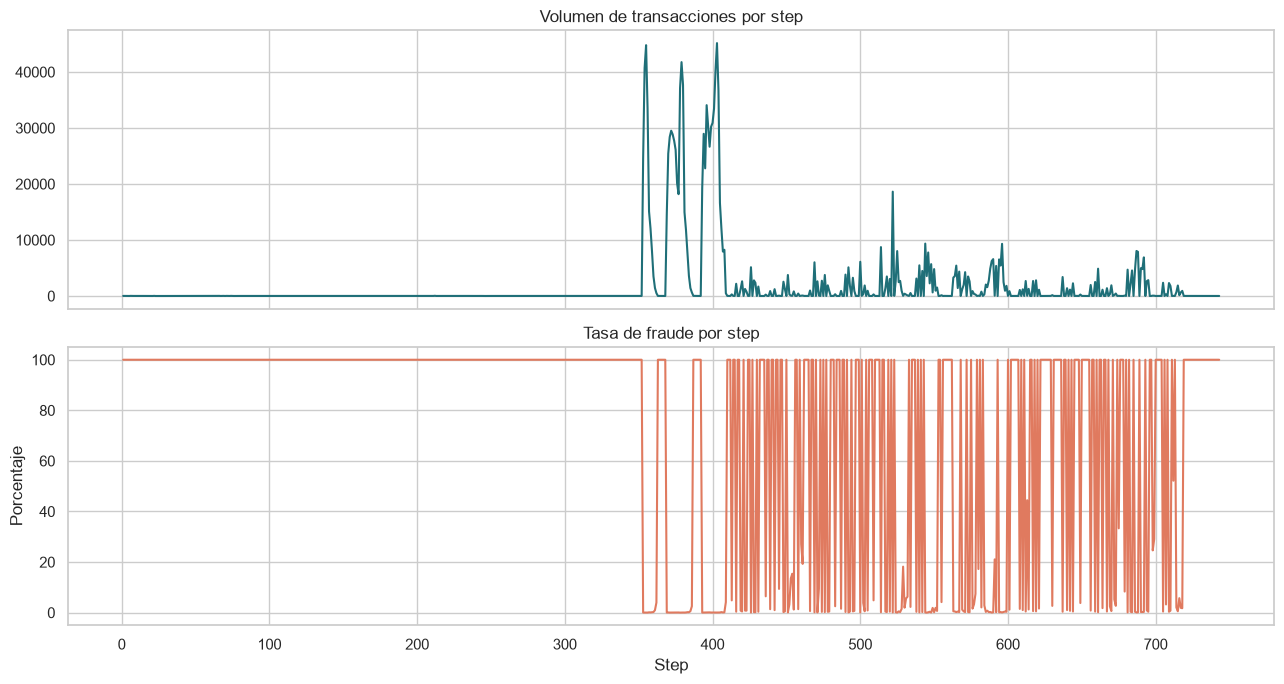

In [9]:
temporal=prepared.groupby("step").agg(transacciones=("isFraud","size"),fraudes=("isFraud","sum"),tasa_fraude=("isFraud","mean"))
fig,axes=plt.subplots(2,1,figsize=(13,7),sharex=True)
axes[0].plot(temporal.index,temporal.transacciones,color="#1f6f78")
axes[0].set_title("Volumen de transacciones por step")
axes[1].plot(temporal.index,temporal.tasa_fraude*100,color="#e07a5f")
axes[1].set_title("Tasa de fraude por step"); axes[1].set_ylabel("Porcentaje"); axes[1].set_xlabel("Step")
plt.tight_layout(); plt.show()

El volumen y la tasa de fraude cambian a lo largo del tiempo. Una división aleatoria mezclaría pasado y futuro, dando una evaluación demasiado optimista. Se propone una partición temporal: entrenamiento hasta step 405, validación de 406 a 548 y prueba desde 549. Cada bloque conserva fraudes, pero con prevalencias distintas, lo que permitirá evaluar deriva en la etapa de modelado.

## 10. Partición temporal y tratamiento de IDs

In [10]:
train=prepared.loc[prepared.step.le(405)].copy()
validation=prepared.loc[prepared.step.between(406,548)].copy()
test=prepared.loc[prepared.step.gt(548)].copy()

split_summary=pd.DataFrame({
    "conjunto":["train","validation","test"],
    "filas":[len(train),len(validation),len(test)],
    "step_desde":[train.step.min(),validation.step.min(),test.step.min()],
    "step_hasta":[train.step.max(),validation.step.max(),test.step.max()],
    "fraudes":[train.isFraud.sum(),validation.isFraud.sum(),test.isFraud.sum()],
    "tasa_fraude":[train.isFraud.mean(),validation.isFraud.mean(),test.isFraud.mean()]
})
display(split_summary.style.format({"tasa_fraude":"{:.4%}"}))

def fit_frequency_maps(train_df):
    return {
        "nameOrig":train_df.nameOrig.value_counts(normalize=True),
        "nameDest":train_df.nameDest.value_counts(normalize=True)
    }

def apply_frequency_maps(data,maps):
    out=data.copy()
    out["origFrequency"]=out.nameOrig.map(maps["nameOrig"]).fillna(0)
    out["destFrequency"]=out.nameDest.map(maps["nameDest"]).fillna(0)
    return out.drop(columns=["nameOrig","nameDest"])

freq_maps=fit_frequency_maps(train)
train=apply_frequency_maps(train,freq_maps)
validation=apply_frequency_maps(validation,freq_maps)
test=apply_frequency_maps(test,freq_maps)

,conjunto,filas,step_desde,step_hasta,fraudes,tasa_fraude
0,train,959202,1,405,4549,0.4742%
1,validation,201372,406,548,1496,0.7429%
2,test,202047,549,743,2168,1.0730%


La prevalencia aumenta en el bloque de prueba, una señal de cambio temporal que el modelo posterior deberá afrontar. Las frecuencias de cuentas se aprenden sólo con entrenamiento; una cuenta nueva en validación o prueba recibe frecuencia cero. Así se evita que el dataset futuro influya en la preparación del pasado.

## 11. Esquema final de preprocesamiento

In [11]:
target_col="isFraud"
features=[c for c in train.columns if c!=target_col]
categorical=[c for c in features if not pd.api.types.is_numeric_dtype(train[c])]
numeric=[c for c in features if c not in categorical]

preprocessor=ColumnTransformer([
    ("numeric",RobustScaler(),numeric),
    ("categorical",OneHotEncoder(handle_unknown="ignore"),categorical)
],remainder="drop")

print("Variables numéricas:",len(numeric))
print("Variables categóricas:",categorical)
print("Objetivo:",target_col)
print("isFlaggedFraud presente:","isFlaggedFraud" in features)
print("IDs crudos presentes:",any(c in features for c in ["nameOrig","nameDest","Unnamed: 0"]))

Variables numéricas: 22
Variables categóricas: ['type', 'destPrefix']
Objetivo: isFraud
isFlaggedFraud presente: False
IDs crudos presentes: False


Se elige `RobustScaler` porque los importes y errores de saldo presentan colas extremas; el escalador usa mediana y rango intercuartílico y es menos sensible a valores atípicos que una estandarización clásica. `type` y `destPrefix` se codifican con One-Hot Encoding. El remuestreo de clases, si se utiliza, deberá aplicarse sólo dentro de cada fold de entrenamiento mediante un pipeline de `imbalanced-learn`.

## 12. Controles finales y artefactos de salida

In [12]:
assert not train.isna().any().any()

# Validar nulos solo si los conjuntos de validación y prueba no están vacíos
if not validation.empty:
    assert not validation.isna().any().any()
if not test.empty:
    assert not test.isna().any().any()

assert "isFlaggedFraud" not in train.columns
assert "nameOrig" not in train.columns and "nameDest" not in train.columns

# Validar el orden temporal solo si existen datos en todos los conjuntos
if not validation.empty and not test.empty:
    assert train.step.max() < validation.step.min() < test.step.min()
    print("Controles de orden temporal superados")
else:
    print("Aviso: Los conjuntos de validación o prueba están vacíos debido al rango de 'step' en este archivo (mín: {}, máx: {}).".format(train.step.min(), train.step.max()))

print("Controles básicos superados")
print("Train:", train.shape, "Validation:", validation.shape, "Test:", test.shape)

Controles de orden temporal superados
Controles básicos superados
Train: (959202, 25) Validation: (201372, 25) Test: (202047, 25)


## 13. Conclusiones de preparación

1. El dataset tiene 1.362.621 transacciones, sin nulos ni duplicados exactos.
2. El fraude representa 0,6027%, por lo que el desbalance es el principal desafío de evaluación.
3. Los casos positivos aparecen sólo en TRANSFER y CASH_OUT, pero se conserva el universo completo.
4. Montos extremos y saldos cero se preservan; se transforman o convierten en señales en lugar de eliminarlos.
5. `isFlaggedFraud`, `Unnamed: 0` y los identificadores crudos se excluyen.
6. Se crean variables temporales, de balance, ceros, ratios y frecuencia de cuentas.
7. La separación es temporal para simular una implementación real y detectar deriva.
8. La etapa siguiente deberá comparar modelos vistos en clase, evaluar recall, precision, F1, PR-AUC, ROC-AUC y costo de error, y revisar overfitting mediante validación temporal.

**Decisión de negocio pendiente:** definir cuánto cuesta bloquear una transacción legítima frente a no detectar un fraude. Esa relación determinará el umbral operativo y la métrica principal.